
# Missouri State Expenditures: Travel Spending Drift Analysis

**Author:** Angie Crews  
**Date:** November 2026  
**Course:** Continuous Intelligence — Module 5

## 1. Project Overview

This project uses Missouri State Expenditures travel data to examine changes in spending patterns.

The goal is to compare reference and current spending periods to identify possible drift in travel expenditures.

The analysis will use Python to load and validate the data, calculate spending metrics, compare results, and create visualizations.

## Data Source

Missouri State Expenditures — 2026

[Missouri Open Data Portal](https://data.mo.gov/Government-Administration/2026-State-Expenditures/gndj-tfr3/about_data)

## Project Objectives

- Examine travel spending patterns.
- Establish a reference baseline.
- Compare reference and current spending.
- Identify possible drift.
- Visualize and interpret the results.


## 2. Load and Validate Data

This section loads Missouri State Expenditures data for fiscal years 2022 through 2026.

The datasets will be checked for consistent columns, data types, and record counts before analyzing travel spending.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

# STEP 1: Locate the project data folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

data_dir = project_root / "data"

# STEP 2: Locate the five expenditure files
files = sorted(data_dir.glob("20??_State_Expenditures*.csv"))

print(f"Files found: {len(files)}")


# STEP 3: Inspect each dataset
for file in files:
    df = pl.read_csv(
        file,
        infer_schema=False,
        ignore_errors=False,
    )

    print(f"\nFile: {file.name}")
    print(f"Records: {df.height}")
    print(f"Columns: {df.width}")
    print(f"Column names: {df.columns}")
    print(f"Data types: {df.dtypes}")

Files found: 5

File: 2022_State_Expenditures_20261109.csv
Records: 96924
Columns: 6
Column names: ['Fiscal Year', 'Agency Name', 'Category Description', 'Detail Description', 'Vendor Name', 'Payments Total']
Data types: [String, String, String, String, String, String]

File: 2023_State_Expenditures_20261109.csv
Records: 107523
Columns: 6
Column names: ['Fiscal Year', 'Agency Name', 'Category Description', 'Detail Description', 'Vendor Name', 'Payments Total']
Data types: [String, String, String, String, String, String]

File: 2024_State_Expenditures_20261109.csv
Records: 110923
Columns: 6
Column names: ['Fiscal Year', 'Agency Name', 'Category Description', 'Detail Description', 'Vendor Name', 'Payments Total']
Data types: [String, String, String, String, String, String]

File: 2025_State_Expenditures_20261109.csv
Records: 108334
Columns: 6
Column names: ['Fiscal Year', 'Agency Name', 'Category Description', 'Detail Description', 'Vendor Name', 'Payments Total']
Data types: [String, St


## 3. Prepare Travel Spending Data

This section prepares the Missouri State Expenditures data for drift analysis.

The data will be filtered to include only travel expenditures. Payment amounts will be converted to numeric values so spending can be compared across fiscal years.

The goal is to establish a historical baseline and identify changes in travel spending.


In [2]:
# STEP 4: Filter and prepare travel expenditures

travel_data = []

for file in files:
    df = pl.read_csv(
        file,
        infer_schema=False,
        ignore_errors=False,
    )

    # Keep only travel expenditures
    df = df.filter(
        pl.col("Category Description").str.strip_chars().str.to_uppercase() == "TRAVEL"
    )

    # Convert payment amounts to numbers
    df = df.with_columns(
        pl.col("Payments Total")
        .str.replace_all(",", "")
        .str.replace_all(r"[$\s]", "")
        .cast(pl.Float64, strict=False)
        .alias("payment_amount")
    )

    # Store the prepared travel records
    travel_data.append(df)

    print(f"\nFile: {file.name}")
    print(f"Travel records: {df.height}")
    print(f"Total travel spending: ${df['payment_amount'].sum():,.2f}")


File: 2022_State_Expenditures_20261109.csv
Travel records: 26629
Total travel spending: $22,330,482.40

File: 2023_State_Expenditures_20261109.csv
Travel records: 36560
Total travel spending: $32,951,229.70

File: 2024_State_Expenditures_20261109.csv
Travel records: 38691
Total travel spending: $38,108,544.15

File: 2025_State_Expenditures_20261109.csv
Travel records: 38746
Total travel spending: $39,229,482.41

File: 2026_State_Expenditures_20261029.csv
Travel records: 37402
Total travel spending: $39,806,024.51


In [3]:
# STEP 5: Validate travel payment amounts

for file, df in zip(files, travel_data):
    missing_payments = df["payment_amount"].null_count()

    print(f"{file.name[:4]}:")
    print(f"  Travel records: {df.height:,}")
    print(f"  Missing payment amounts: {missing_payments:,}")

2022:
  Travel records: 26,629
  Missing payment amounts: 0
2023:
  Travel records: 36,560
  Missing payment amounts: 0
2024:
  Travel records: 38,691
  Missing payment amounts: 0
2025:
  Travel records: 38,746
  Missing payment amounts: 0
2026:
  Travel records: 37,402
  Missing payment amounts: 0


## 4. Establish the Historical Baseline

This section uses Missouri travel expenditures from 2022 through 2024 as the historical reference period.

Travel spending from 2025 and 2026 will be compared against this baseline to identify possible changes in spending patterns.

The analysis will compare total spending, average payment amounts, and the number of travel transactions. Fiscal-year coverage will also be considered when interpreting the results.

In [5]:
# STEP 6: Calculate annual travel spending metrics

annual_metrics = []

# Calculate spending metrics for each fiscal year
for file, df in zip(files, travel_data):
    year = int(file.name[:4])

    total_spending = df["payment_amount"].sum()
    transaction_count = df.height
    average_payment = df["payment_amount"].mean()

    annual_metrics.append(
        {
            "Fiscal Year": year,
            "Total Spending": total_spending,
            "Transactions": transaction_count,
            "Average Payment": average_payment,
        }
    )

# Create a summary table with numeric values
annual_summary = pl.DataFrame(annual_metrics).sort("Fiscal Year")

# Format the summary table for display
formatted_summary = annual_summary.with_columns(
    pl.col("Total Spending").map_elements(
        lambda x: f"${x:,.2f}",
        return_dtype=pl.String,
    ),
    pl.col("Transactions").map_elements(
        lambda x: f"{x:,}",
        return_dtype=pl.String,
    ),
    pl.col("Average Payment").map_elements(
        lambda x: f"${x:,.2f}",
        return_dtype=pl.String,
    ),
)

# Display the formatted results
print("Annual Missouri Travel Spending Summary")
display(formatted_summary)

Annual Missouri Travel Spending Summary


Fiscal Year,Total Spending,Transactions,Average Payment
i64,str,str,str
2022,"""$22,330,482.40""","""26,629""","""$838.58"""
2023,"""$32,951,229.70""","""36,560""","""$901.29"""
2024,"""$38,108,544.15""","""38,691""","""$984.95"""
2025,"""$39,229,482.41""","""38,746""","""$1,012.48"""
2026,"""$39,806,024.51""","""37,402""","""$1,064.28"""


In [7]:
# STEP 7: Establish the historical baseline (2022-2024)

# Select the reference years
baseline_data = annual_summary.filter(pl.col("Fiscal Year").is_between(2022, 2024))

# Calculate baseline averages
baseline_metrics = baseline_data.select(
    pl.col("Total Spending").mean().alias("Baseline Spending"),
    pl.col("Transactions").mean().alias("Baseline Transactions"),
    pl.col("Average Payment").mean().alias("Baseline Average Payment"),
)


# Format the baseline results for display
formatted_baseline = baseline_metrics.with_columns(
    pl.col("Baseline Spending").map_elements(
        lambda x: f"${x:,.2f}",
        return_dtype=pl.String,
    ),
    pl.col("Baseline Transactions").map_elements(
        lambda x: f"{x:,.0f}",
        return_dtype=pl.String,
    ),
    pl.col("Baseline Average Payment").map_elements(
        lambda x: f"${x:,.2f}",
        return_dtype=pl.String,
    ),
)

# Display the formatted baseline
print("Missouri Travel Spending Historical Baseline (2022-2024)")
display(formatted_baseline)

Missouri Travel Spending Historical Baseline (2022-2024)


Baseline Spending,Baseline Transactions,Baseline Average Payment
str,str,str
"""$31,130,085.42""","""33,960""","""$908.27"""


In [8]:
# STEP 8: Compare current spending to the historical baseline

# Select the comparison years (2025-2026)
current_data = annual_summary.filter(pl.col("Fiscal Year").is_between(2025, 2026))

# Get the historical baseline values
baseline_spending = baseline_metrics["Baseline Spending"][0]
baseline_transactions = baseline_metrics["Baseline Transactions"][0]
baseline_payment = baseline_metrics["Baseline Average Payment"][0]

# Calculate differences and percentage changes
drift_comparison = current_data.with_columns(
    (pl.col("Total Spending") - baseline_spending).alias("Spending Difference"),
    ((pl.col("Total Spending") - baseline_spending) / baseline_spending * 100).alias(
        "Spending Change %"
    ),
    (pl.col("Transactions") - baseline_transactions).alias("Transaction Difference"),
    (
        (pl.col("Transactions") - baseline_transactions) / baseline_transactions * 100
    ).alias("Transaction Change %"),
    (pl.col("Average Payment") - baseline_payment).alias("Payment Difference"),
    ((pl.col("Average Payment") - baseline_payment) / baseline_payment * 100).alias(
        "Payment Change %"
    ),
)

# Format results for display without changing numeric data
formatted_comparison = drift_comparison.select(
    pl.col("Fiscal Year"),
    pl.col("Spending Difference").map_elements(
        lambda x: f"${x:,.2f}", return_dtype=pl.String
    ),
    pl.col("Spending Change %").map_elements(
        lambda x: f"{x:+.2f}%", return_dtype=pl.String
    ),
    pl.col("Transaction Difference").map_elements(
        lambda x: f"{x:+,.0f}", return_dtype=pl.String
    ),
    pl.col("Transaction Change %").map_elements(
        lambda x: f"{x:+.2f}%", return_dtype=pl.String
    ),
    pl.col("Payment Difference").map_elements(
        lambda x: f"${x:+,.2f}", return_dtype=pl.String
    ),
    pl.col("Payment Change %").map_elements(
        lambda x: f"{x:+.2f}%", return_dtype=pl.String
    ),
)

print("Missouri Travel Spending Drift Comparison (2025-2026)")
display(formatted_comparison)

Missouri Travel Spending Drift Comparison (2025-2026)


Fiscal Year,Spending Difference,Spending Change %,Transaction Difference,Transaction Change %,Payment Difference,Payment Change %
i64,str,str,str,str,str,str
2025,"""$8,099,396.99""","""+26.02%""","""+4,786""","""+14.09%""","""$+104.21""","""+11.47%"""
2026,"""$8,675,939.09""","""+27.87%""","""+3,442""","""+10.14%""","""$+156.00""","""+17.18%"""


## 5. Detect Potential Spending Drift

This section evaluates changes in Missouri travel spending against the historical baseline.

A 10% threshold is used to identify changes in spending, transaction counts, and average payment amounts that may indicate drift.

In [10]:
# STEP 9: Detect potential spending drift

# Set the drift detection threshold
drift_threshold = 10.0

# Evaluate each year against the historical baseline
drift_results = drift_comparison.select(
    pl.col("Fiscal Year"),
    (pl.col("Spending Change %").abs() > drift_threshold).alias("Spending Drift"),
    (pl.col("Transaction Change %").abs() > drift_threshold).alias("Transaction Drift"),
    (pl.col("Payment Change %").abs() > drift_threshold).alias("Payment Drift"),
)

# Display drift detection results
print("Missouri Travel Spending Drift Detection")
print(f"Drift threshold: {drift_threshold}%")

display(drift_results)

Missouri Travel Spending Drift Detection
Drift threshold: 10.0%


Fiscal Year,Spending Drift,Transaction Drift,Payment Drift
i64,bool,bool,bool
2025,true,true,true
2026,true,true,true


## 6. Visualize Travel Spending Drift

This section uses Matplotlib to visualize Missouri travel spending from 2022 through 2026.

The chart compares annual travel spending with the 2022–2024 historical baseline to help identify changes in spending patterns.

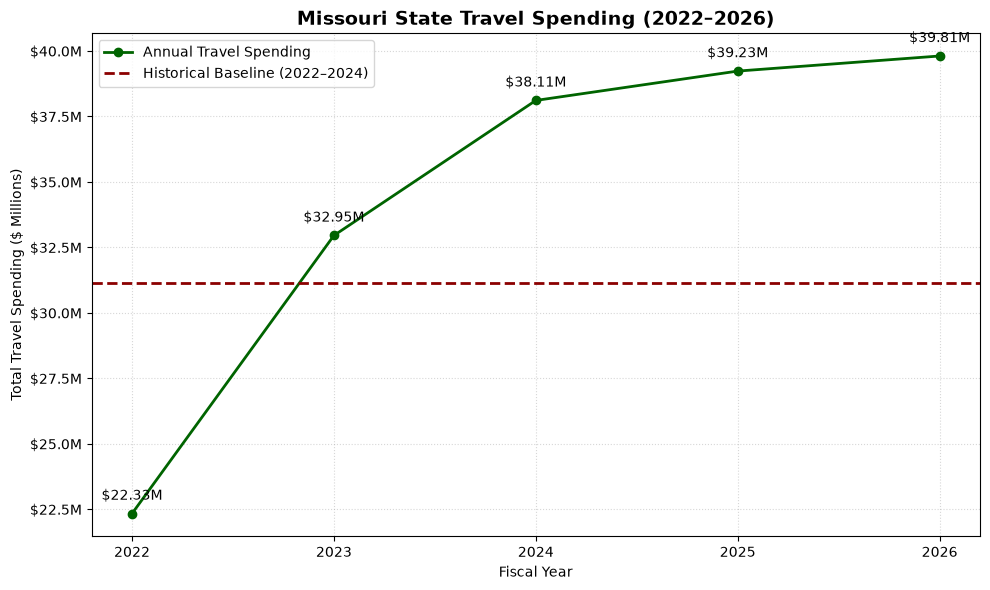

In [11]:
# STEP 10: Visualize Missouri travel spending drift


# Get annual spending data
years = annual_summary["Fiscal Year"].to_list()
spending = annual_summary["Total Spending"].to_list()

# Get the historical baseline
baseline_value = baseline_metrics["Baseline Spending"][0]

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

# Plot annual travel spending
ax.plot(
    years,
    spending,
    marker="o",
    linewidth=2,
    color="darkgreen",
    label="Annual Travel Spending",
)

# Plot historical baseline
ax.axhline(
    y=baseline_value,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Historical Baseline (2022–2024)",
)

# Format the chart
ax.set_title(
    "Missouri State Travel Spending (2022–2026)",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Fiscal Year")
ax.set_ylabel("Total Travel Spending ($ Millions)")

# Display spending in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x / 1_000_000:,.1f}M"))

ax.set_xticks(years)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()

# Add dollar labels to each point
for year, amount in zip(years, spending):
    ax.annotate(
        f"${amount / 1_000_000:,.2f}M",
        (year, amount),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
    )

plt.tight_layout()
plt.show()

## 7. Interpret the Drift Detection Results

### STEP 11: Analysis and Findings

**Historical Spending Patterns**

Missouri travel spending increased from $22.33 million in 2022 to $39.81 million in 2026. The historical baseline for 2022–2024 was approximately $31.13 million annually.

**Drift Detection Results**

Using a 10% threshold, the analysis identified potential drift in all three metrics for both 2025 and 2026:

- Total travel spending
- Number of travel transactions
- Average travel payment

In 2026, total spending was 27.87% above the historical baseline, while the average payment increased by 17.18%.

**Interpretation**

The results suggest that Missouri travel spending patterns have changed compared with earlier years. Although the number of transactions decreased from 2025 to 2026, the average payment continued to increase.

Spending was already increasing during the historical baseline period, so these results may reflect an ongoing trend rather than a sudden change.

**Limitations**

This analysis uses annual expenditure data and a 10% threshold to identify potential drift. It does not determine the cause of spending changes or establish statistical significance.

Additional analysis would be needed to determine whether changes are related to travel costs, agency activity, or other factors. The completeness and comparability of each fiscal year's data should also be verified.

**Conclusion**

The analysis identified potential drift in Missouri travel expenditures during 2025 and 2026. Monitoring these changes over time could help identify unusual spending patterns and support better financial oversight.

## 8. Save Analysis Results

This section saves the annual travel spending summary, drift detection results, and visualization to the artifacts folder for documentation and future reference.

In [12]:
# STEP 12: Save Missouri travel spending analysis results

from pathlib import Path

import matplotlib.pyplot as plt

# Locate the artifacts folder
artifacts_dir = project_root / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Save annual spending summary
annual_summary.write_csv(artifacts_dir / "missouri_travel_annual_summary.csv")

# Save drift detection results
drift_results.write_csv(artifacts_dir / "missouri_travel_drift_results.csv")

# Save the chart created in STEP 10
fig.savefig(
    artifacts_dir / "missouri_travel_spending_chart.png",
    dpi=300,
    bbox_inches="tight",
)

print("Missouri Travel Spending Analysis Results Saved")
print(f"Output folder: {artifacts_dir}")
print("Annual summary: Saved")
print("Drift detection results: Saved")
print("Spending chart: Saved")

Missouri Travel Spending Analysis Results Saved
Output folder: c:\Repos\Continuous Intelligence (44630)\cintel-05-drift-detection\artifacts
Annual summary: Saved
Drift detection results: Saved
Spending chart: Saved
